In [1]:
import yaml
import numpy as np
from matplotlib import pyplot as plt

# --- Custom Utility Module --
from flux_history import FluxHistory
from mineral_utils import Paleodetector, slice_spectrum_etch

In [2]:
mineral_name =  "Olivine"

sample_area_cm2 = 0.2*0.1

overburden_history = {
    "initial_depth": 0.3
}

h_obs_km = 1.

flux_history_base = FluxHistory(baseline={"kind": "Baseline", "h_obs_km": h_obs_km})
flux_history_base_laschamp = FluxHistory(baseline={"kind": "Baseline", "h_obs_km": h_obs_km}, excursions=[{"start_time_kyr" : -42., "end_time_kyr" : -40., "geomagnetic_cutoff" : 0.}])
flux_history_sn250 = FluxHistory(baseline={"kind": "Baseline", "h_obs_km": h_obs_km}, events=[{"start_time_kyr":-50., "template": {"kind":"SN", "distance_pc": 250., "h_obs_km": h_obs_km}}])
flux_history_sn250_laschamp = FluxHistory(baseline={"kind": "Baseline", "h_obs_km": h_obs_km}, events=[{"start_time_kyr":-50., "template": {"kind":"SN", "distance_pc": 250., "h_obs_km": h_obs_km}}], excursions=[{"start_time_kyr" : -42., "end_time_kyr" : -40., "geomagnetic_cutoff" : 0.}])

In [3]:
MINERAL_LIBRARY = yaml.safe_load(open('Data/mineral_library.yaml', 'r'))
mineral_config = MINERAL_LIBRARY.get(mineral_name)

In [4]:
exposure_times = np.array([41.4, 30., 13.1, 10.96, 9.5, 8.64, 7.65])
exposure_times_err = np.array([1., 2., 0.7, 0.15, 0.5, 0.06, 0.12])
names = np.array(["Laschamp", "Lemptegy", "Come", "Dome", "Pariou", "La Vache", "Montcineyre"], dtype=str)

In [5]:
minerals = []
fission_tracks_list = []
radioneutron_tracks_list = []
cosmo_tracks_simple_list = []
cosmo_tracks_simple_laschamp_list = []
cosmo_tracks_SN250_list = []
cosmo_tracks_SN250_laschamp_list = []

for age in exposure_times:

    mineral = Paleodetector(mineral_config, total_age_kyr=age, flux_history=flux_history_base, overburden_history=overburden_history)
    minerals.append(mineral)

    x_bins, fission_tracks = mineral.integrate_fission_spectrum()
    fission_tracks_list.append(fission_tracks)
    x_bins, radioneutron_tracks = mineral.integrate_background_neutron_spectrum()
    radioneutron_tracks_list.append(radioneutron_tracks)
    x_bins, cosmo_tracks_simple = mineral.integrate_all_particles()
    cosmo_tracks_simple_list.append(cosmo_tracks_simple)
    x_bins, cosmo_tracks_simple_laschamp = mineral.integrate_all_particles(flux_history=flux_history_base_laschamp)
    cosmo_tracks_simple_laschamp_list.append(cosmo_tracks_simple_laschamp)
    x_bins, cosmo_tracks_SN250 = mineral.integrate_all_particles(flux_history=flux_history_sn250)
    cosmo_tracks_SN250_list.append(cosmo_tracks_SN250)
    x_bins, cosmo_tracks_SN250_laschamp = mineral.integrate_all_particles(flux_history=flux_history_sn250_laschamp)
    cosmo_tracks_SN250_laschamp_list.append(cosmo_tracks_SN250_laschamp)

x_mids = x_bins[:-1] + np.diff(x_bins) / 2     

Interpolating overburden history...
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 7.627 GeV in 67 steps
  secondary_neutron neutrons produced by mu-, mu+, neutron above the sample (StdRock runs), recoils from the neutron runs
Calculating spontaneous fission background...
Calculating radiogenic neutron contribution from fission_n
Calculating radiogenic neutron contribution from alpha_n


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [02:45<00:00, 41.27s/it]


Interpolating overburden history...
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 7.627 GeV in 67 steps
  secondary_neutron neutrons produced by mu-, mu+, neutron above the sample (StdRock runs), recoils from the neutron runs
Calculating spontaneous fission background...
Calculating radiogenic neutron contribution from fission_n
Calculating radiogenic neutron contribution from alpha_n


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [02:23<00:00, 35.83s/it]


Interpolating overburden history...
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 7.627 GeV in 67 steps
  secondary_neutron neutrons produced by mu-, mu+, neutron above the sample (StdRock runs), recoils from the neutron runs
Calculating spontaneous fission background...
Calculating radiogenic neutron contribution from fission_n
Calculating radiogenic neutron contribution from alpha_n


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [02:16<00:00, 34.18s/it]


... (4 outputs left out)

Interpolating overburden history...
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 7.627 GeV in 67 steps
  secondary_neutron neutrons produced by mu-, mu+, neutron above the sample (StdRock runs), recoils from the neutron runs
Calculating spontaneous fission background...
Calculating radiogenic neutron contribution from fission_n
Calculating radiogenic neutron contribution from alpha_n


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [02:15<00:00, 34.00s/it]


Interpolating overburden history...
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 7.627 GeV in 67 steps
  secondary_neutron neutrons produced by mu-, mu+, neutron above the sample (StdRock runs), recoils from the neutron runs
Calculating spontaneous fission background...
Calculating radiogenic neutron contribution from fission_n
Calculating radiogenic neutron contribution from alpha_n


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [02:24<00:00, 36.08s/it]


In [6]:
sliced_bkg = np.asarray([slice_spectrum_etch(radioneutron_tracks_list[i]+fission_tracks_list[i], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='plasma') for i in range(len(exposure_times))])

sliced_cosmo_simple = np.asarray([slice_spectrum_etch(cosmo_tracks_simple_list[i]["total"], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='plasma') for i in range(len(exposure_times))])
sliced_cosmo_simple_laschamp = np.asarray([slice_spectrum_etch(cosmo_tracks_simple_laschamp_list[i]["total"], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='plasma') for i in range(len(exposure_times))])

sliced_cosmo_SN250 = np.asarray([slice_spectrum_etch(cosmo_tracks_SN250_list[i]["total"], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='plasma') for i in range(len(exposure_times))])
sliced_cosmo_SN250_laschamp = np.asarray([slice_spectrum_etch(cosmo_tracks_SN250_laschamp_list[i]["total"], sample_area_cm2=sample_area_cm2, sample_density_g_cm3=mineral_config["density_g_cm3"], etch_type='plasma') for i in range(len(exposure_times))])

In [7]:
summed_simple = np.sum(sliced_cosmo_simple + sliced_bkg, axis=-1)
summed_simple_laschamp = np.sum(sliced_cosmo_simple_laschamp + sliced_bkg, axis=-1)
summed_SN250 = np.sum(sliced_cosmo_SN250 + sliced_bkg, axis=-1)
summed_SN250_laschamp = np.sum(sliced_cosmo_SN250_laschamp + sliced_bkg, axis=-1)

In [8]:
fig, ax = plt.subplots(figsize=[7, 5])

import matplotlib.patches as patches
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset

ax.errorbar(exposure_times, summed_simple, yerr= np.sqrt(summed_simple), label="Normal scenario", linewidth=1.8, color='C0', marker='o', markersize=1., linestyle='--', capsize=0)
ax.errorbar(exposure_times, summed_simple_laschamp, yerr= np.sqrt(summed_simple_laschamp), label="Normal scenario + Laschamp", linewidth=1.2, color='C0', marker='o', markersize=0.4, linestyle='-.', capsize=0)

ax.errorbar(exposure_times, summed_SN250, yerr= np.sqrt(summed_SN250), label="With SN @ 250 pc", linewidth=1.8, color='C1', marker='o', markersize=1., linestyle='--', capsize=0)
ax.errorbar(exposure_times, summed_SN250_laschamp, yerr= np.sqrt(summed_SN250_laschamp), label="With SN @ 250 pc + Laschamp", linewidth=1.2, color='C1', marker='o', markersize=0.4, linestyle='-.', capsize=0)

axins = zoomed_inset_axes(ax, zoom=2., loc='upper left',bbox_to_anchor=(0.15, 0.6, 0.8, 0.4), bbox_transform=ax.transAxes)
axins.errorbar(exposure_times, summed_simple, yerr= np.sqrt(summed_simple), label="Normal scenario", linewidth=1.8, color='C0', marker='o', markersize=1., linestyle='--', capsize=0)

axins.errorbar(exposure_times, summed_SN250, yerr= np.sqrt(summed_SN250), label="With SN @ 250 pc", linewidth=1.8, color='C1', marker='o', markersize=1., linestyle='--', capsize=0)


for i, age in enumerate(exposure_times):
    ax.axvspan(age-exposure_times_err[i], age+exposure_times_err[i], color='grey', alpha=0.4)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.9*summed_simple[i]),
                                   2 * exposure_times_err[i], 0.2*summed_simple[i], 
                                   linewidth = 0.1, facecolor = "C0", edgecolor = "C0", alpha = 0.4)
    ax.add_patch(rect)

    rect  = patches.Rectangle((age-exposure_times_err[i], 0.7*summed_simple[i]),
                                   2 * exposure_times_err[i], 0.6*summed_simple[i], 
                                   linewidth = 0.1, facecolor = "C0", edgecolor = "C0", alpha = 0.2)
    ax.add_patch(rect)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.9*summed_SN250[i]),
                                   2 * exposure_times_err[i], 0.2*summed_SN250[i], 
                                   linewidth = 0.1, facecolor = "C1", edgecolor = "C1", alpha = 0.4)
    ax.add_patch(rect)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.7*summed_SN250[i]),
                                   2 * exposure_times_err[i], 0.6*summed_SN250[i], 
                                   linewidth = 0.1, facecolor = "C1", edgecolor = "C1", alpha = 0.2)
    ax.add_patch(rect)


for i, age in enumerate(exposure_times):
    axins.axvspan(age-exposure_times_err[i], age+exposure_times_err[i], color='grey', alpha=0.4)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.9*summed_simple[i]),
                                   2 * exposure_times_err[i], 0.2*summed_simple[i], 
                                   linewidth = 0.1, facecolor = "C0", edgecolor = "C0", alpha = 0.4)
    axins.add_patch(rect)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.7*summed_simple[i]),
                                   2 * exposure_times_err[i], 0.6*summed_simple[i], 
                                   linewidth = 0.1, facecolor = "C0", edgecolor = "C0", alpha = 0.2)
    axins.add_patch(rect)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.9*summed_SN250[i]),
                                   2 * exposure_times_err[i], 0.2*summed_SN250[i], 
                                   linewidth = 0.1, facecolor = "C1", edgecolor = "C1", alpha = 0.4)
    axins.add_patch(rect)
    rect  = patches.Rectangle((age-exposure_times_err[i], 0.7*summed_SN250[i]),
                                   2 * exposure_times_err[i], 0.6*summed_SN250[i], 
                                   linewidth = 0.1, facecolor = "C1", edgecolor = "C1", alpha = 0.2)
    axins.add_patch(rect)

axins.set_xlim(7.3, 14.2)
axins.set_ylim(0.03e5, 0.35e5)
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5", linestyle='--')


ax.set_xlabel(r"Exposure Time (kyr)")
ax.set_ylabel(r"Number of tracks")
ax.legend(fontsize='small', loc='upper right')
plt.show()

ValueError: Image size of 634x346499858 pixels is too large. It must be less than 2^23 in each direction.

<Figure size 700x500 with 2 Axes>

summed_simple shape= (7,) | finite= True | min= 0 | max= 0
summed_simple_laschamp shape= (7,) | finite= True | min= 0 | max= 0
summed_SN250 shape= (7,) | finite= True | min= 0 | max= 0
summed_SN250_laschamp shape= (7,) | finite= True | min= 0 | max= 0


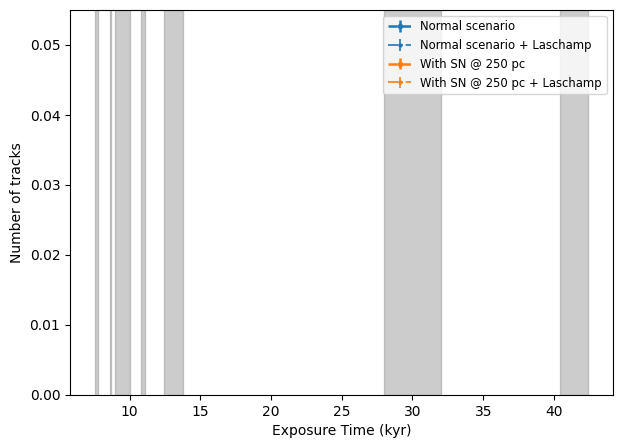

In [9]:
import numpy as np
from matplotlib import pyplot as plt

# --- 诊断：先把四个数组的范围打出来，确认没有异常值 ---
for name in ["summed_simple", "summed_simple_laschamp",
             "summed_SN250", "summed_SN250_laschamp"]:
    a = globals()[name]
    print(name, "shape=", np.shape(a),
          "| finite=", np.isfinite(a).all(),
          "| min=", np.nanmin(a), "| max=", np.nanmax(a))

# --- 清洗非有限值，避免自动缩放被带飞 ---
def clean(a):
    a = np.asarray(a, dtype=float)
    return np.where(np.isfinite(a) & (a > 0), a, np.nan)

ss, sl = clean(summed_simple), clean(summed_simple_laschamp)
sn, snl = clean(summed_SN250), clean(summed_SN250_laschamp)

fig, ax = plt.subplots(figsize=[7, 5])

ax.errorbar(exposure_times, ss, yerr=np.sqrt(ss), label="Normal scenario",
            linewidth=1.8, color='C0', marker='o', markersize=3, linestyle='--', capsize=0)
ax.errorbar(exposure_times, sl, yerr=np.sqrt(sl), label="Normal scenario + Laschamp",
            linewidth=1.2, color='C0', marker='o', markersize=2, linestyle='-.', capsize=0)
ax.errorbar(exposure_times, sn, yerr=np.sqrt(sn), label="With SN @ 250 pc",
            linewidth=1.8, color='C1', marker='o', markersize=3, linestyle='--', capsize=0)
ax.errorbar(exposure_times, snl, yerr=np.sqrt(snl), label="With SN @ 250 pc + Laschamp",
            linewidth=1.2, color='C1', marker='o', markersize=2, linestyle='-.', capsize=0)

# 固定 y 轴从 0 开始，禁止自动缩放到离谱范围
ax.set_ylim(bottom=0)

# 原始的灰色年龄误差区间（只画竖条，不再用 Rectangle）
for i, age in enumerate(exposure_times):
    ax.axvspan(age - exposure_times_err[i], age + exposure_times_err[i],
               color='grey', alpha=0.4)

ax.set_xlabel(r"Exposure Time (kyr)")
ax.set_ylabel(r"Number of tracks")
ax.legend(fontsize='small', loc='upper right')
plt.show()
